# Gauss-law flux loss: Plummer-sphere ablation and robustness

Extends `plummer_sphere_example.ipynb` (Green et al.) with the integral form of Poisson's equation:
$M_{enc}(<R)=R^2\langle\partial\Phi/\partial nangle/G$ on spheres. Terms: **mono** (concentric shells, $M_{enc}$ non-decreasing),
**pos** ($M_{enc}\ge0$, incl. off-centre local spheres), **lower** ($M_{enc}\ge f_b M_{true}$, toy "baryonic" bound), **upper** ($M_{enc}\le(1+\delta)M_{true}$).
All arms keep the repo's stationarity + pointwise $
abla^2\Phi\ge0$ loss; the flux loss is added with weight $\gamma=1$.

Uses the pretrained flow ensemble in `plummer_flow/` (first 16 flows) to estimate $\partial f/\partial\eta$.

In [1]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
import ablation as A
print(A.DEV)

Pytorch version 2.6.0+cu124
Pytorch version 2.6.0+cu124
cuda


## 1. Data: Plummer samples + flow-ensemble gradients (cached after first run)

In [2]:
data = A.build_dataset(n_points=32768, n_flows=16)
{k: tuple(v.shape) for k, v in data.items()}

{'q': (32768, 3), 'p': (32768, 3), 'dq': (32768, 3), 'dp': (32768, 3)}

## 2. Ablation (2 seeds, 1500 steps each)

In [3]:
abl = A.run_ablation(data, seeds=(0, 1), n_steps=1500, verbose=False)
for arm, runs in abl.items():
    print(f"{arm:22s} M_err={np.mean([r['M_err'] for r in runs]):.3f}  phi_rms={np.mean([r['phi_rms'] for r in runs]):.3f}")

C:\Users\joeel\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\autograd\graph.py:823: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:180.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
D:\Graduate Life\Fall 26\deep-potential-master\deep-potential-master\scripts\flow_torch.py:813: UserWarning: This overload of addcmul_ is deprecated:
	addcmul_(Number value, Tensor tensor1, Tensor tensor2)
Consider using one of the following signatures instead:
	addcmul_(Tensor tensor1, Tensor tensor2, *, Number value = 1) (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\python_arg_parser.cpp:1661.)
  exp_avg_sq.mul_(beta2).addcmul_(1 - beta2, grad, grad)


baseline               M_err=0.185  phi_rms=0.038
flux: mono+pos         M_err=0.121  phi_rms=0.022
flux: +lower           M_err=0.323  phi_rms=0.036
flux: +lower+upper     M_err=0.280  phi_rms=0.051


## 3. Robustness to a mis-specified external mass
Scale the assumed bounds by $s$: lower $	o s f_b M_{true}$, upper $	o s(1+\delta)M_{true}$. $s=1$ is the correct bracket.
Truth violates the lower bound for $s>1/f_bpprox3.3$ and the upper bound for $s<1/(1+\delta)pprox0.83$.

In [4]:
rob = A.run_robustness(data, scales=(0.5, 0.8, 1.0, 1.25, 2.0, 3.0, 4.0), seeds=(0,), n_steps=1500)

flux: +lower s=0.5: M_err=0.124 phi_rms=0.017


flux: +lower s=0.8: M_err=0.149 phi_rms=0.019


flux: +lower s=1.0: M_err=0.193 phi_rms=0.022


flux: +lower s=1.25: M_err=0.240 phi_rms=0.036


flux: +lower s=2.0: M_err=0.081 phi_rms=0.014


flux: +lower s=3.0: M_err=0.974 phi_rms=0.098


... (4 outputs left out)

flux: +lower+upper s=1.25: M_err=0.134 phi_rms=0.021


flux: +lower+upper s=2.0: M_err=0.053 phi_rms=0.021


flux: +lower+upper s=3.0: M_err=0.292 phi_rms=0.097


flux: +lower+upper s=4.0: M_err=1.735 phi_rms=0.241


## 4. Figures and table (saved to `figures/`)

| arm | M_enc rel. err | Phi RMS err |
|---|---|---|
| baseline | 0.185 ± 0.063 | 0.038 ± 0.020 |
| flux: mono+pos | 0.121 ± 0.056 | 0.022 ± 0.001 |
| flux: +lower | 0.323 ± 0.130 | 0.036 ± 0.014 |
| flux: +lower+upper | 0.280 ± 0.183 | 0.051 ± 0.027 |


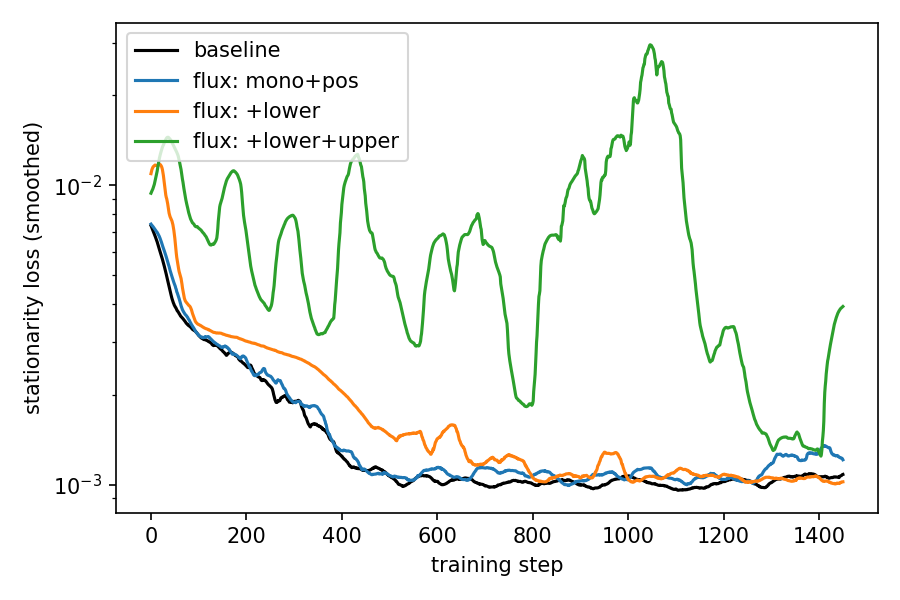

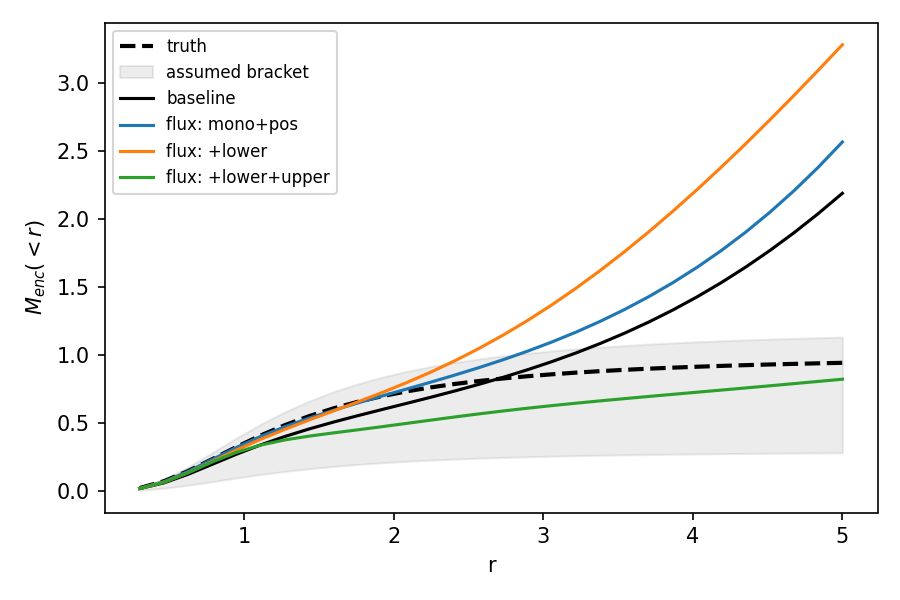

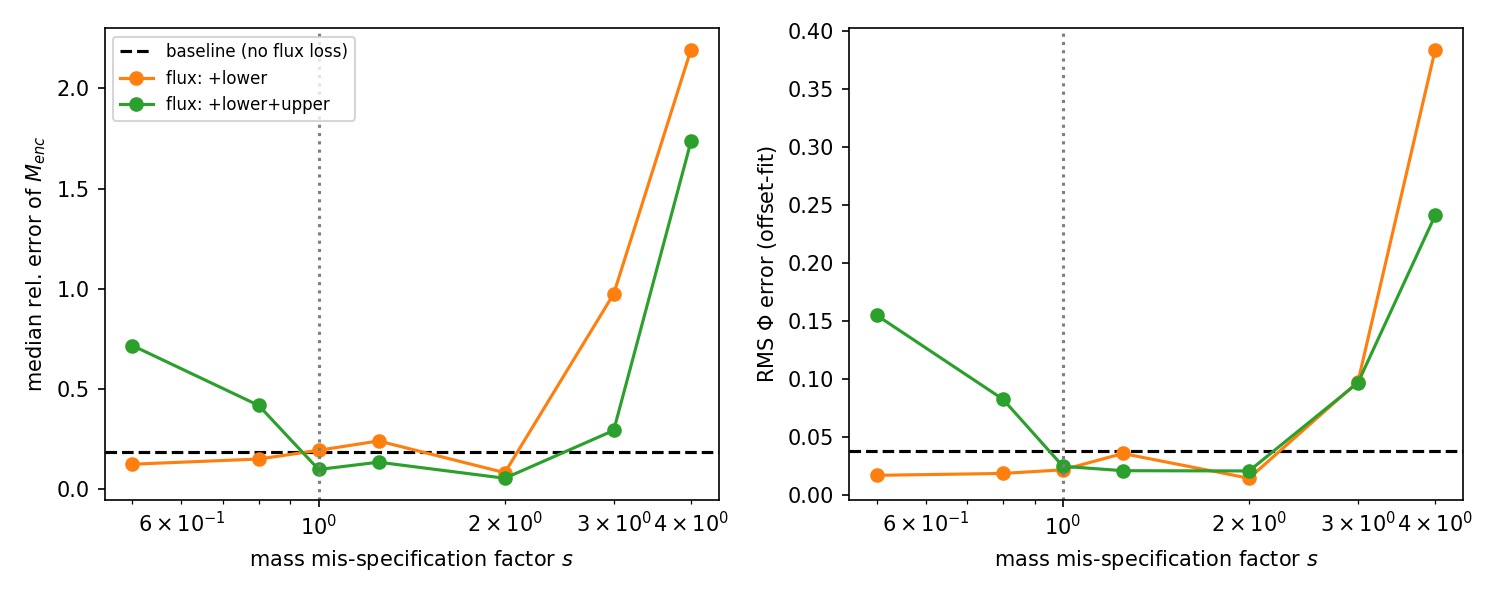

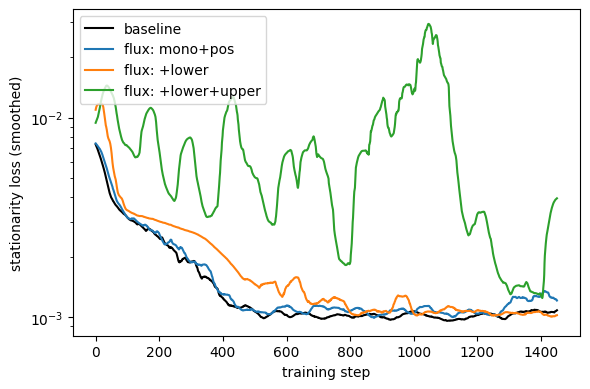

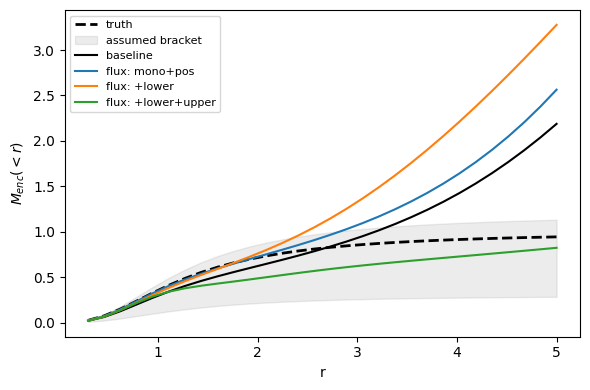

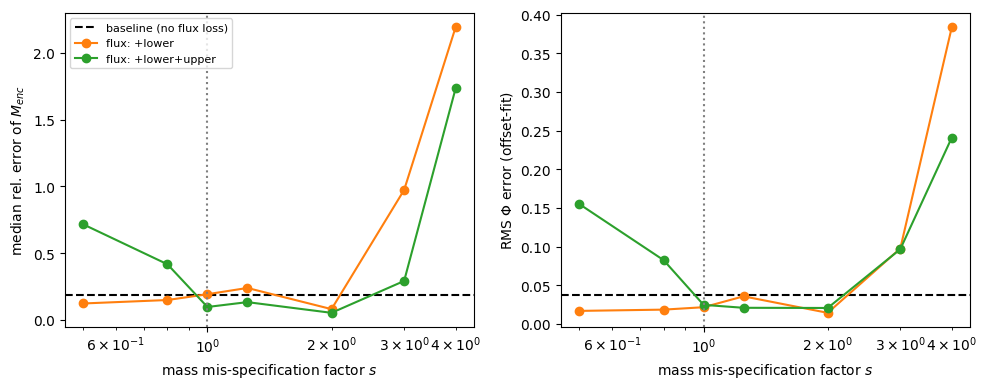

In [5]:
print(A.make_figures(abl, rob))
from IPython.display import Image, display
for f in ("fig1_loss", "fig2_enclosed_mass", "fig3_robustness"):
    display(Image(str(A.FIG / f"{f}.png")))